Fold 1:
  Slope (m): 4.4405
  Intercept (c): 25.5714
  Equation: Y = 4.4405X + 25.5714
  Actual Y:    [35 40]
  Predicted Y: [34.4524 38.8929]
  MSE: 0.7628

Fold 2:
  Slope (m): 4.3333
  Intercept (c): 26.5417
  Equation: Y = 4.3333X + 26.5417
  Actual Y:    [43 48]
  Predicted Y: [43.875  48.2083]
  MSE: 0.4045

Fold 3:
  Slope (m): 4.3598
  Intercept (c): 26.2866
  Equation: Y = 4.3598X + 26.2866
  Actual Y:    [52 57]
  Predicted Y: [52.4451 56.8049]
  MSE: 0.1181

Fold 4:
  Slope (m): 4.3472
  Intercept (c): 26.2917
  Equation: Y = 4.3472X + 26.2917
  Actual Y:    [61 66]
  Predicted Y: [61.0694 65.4167]
  MSE: 0.1726

Fold 5:
  Slope (m): 4.3810
  Intercept (c): 26.1548
  Equation: Y = 4.3810X + 26.1548
  Actual Y:    [70 74]
  Predicted Y: [69.9643 74.3452]
  MSE: 0.0602

Average MSE: 0.3036


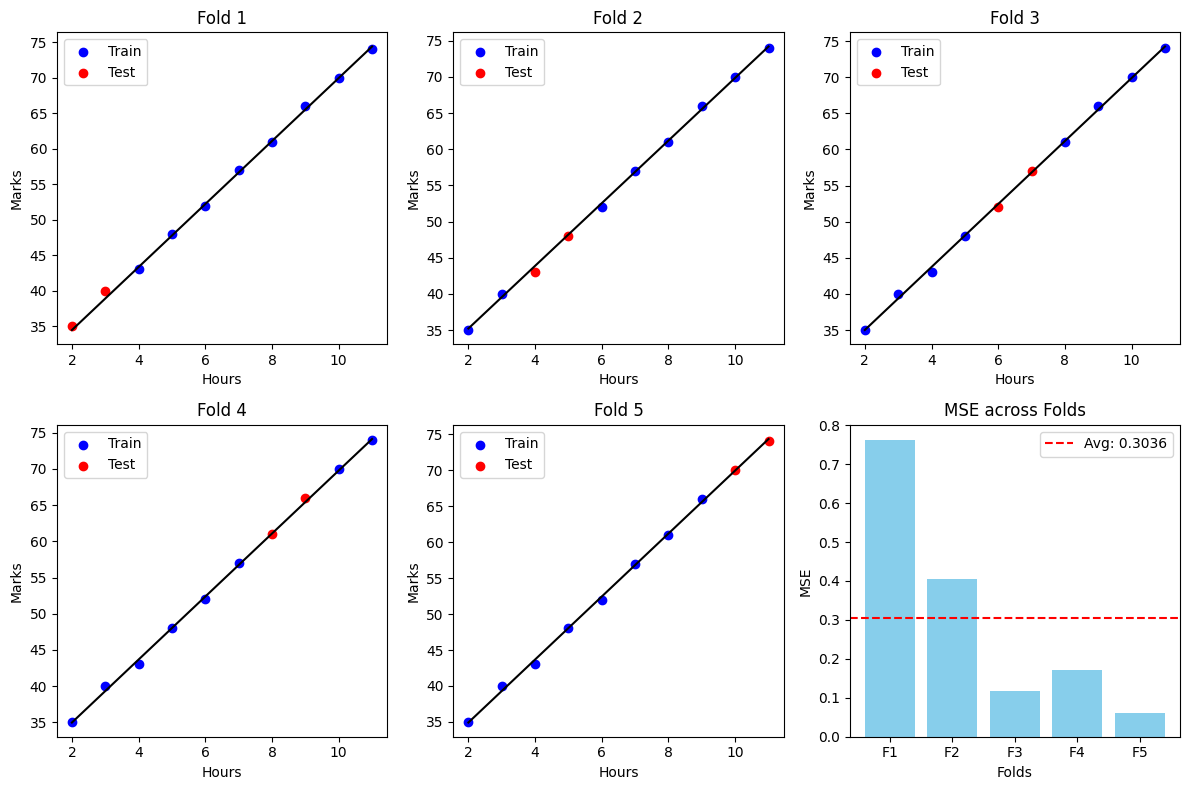

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold

data = pd.read_csv('k_fold_linear_regression_records.csv')
X = data['Hours_Studied'].values
Y = data['Marks'].values

kf = KFold(n_splits=5, shuffle=False)

mse_list = []
fold = 1

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes = axes.flatten()

for train_idx, test_idx in kf.split(X):
    X_train, X_test = X[train_idx], X[test_idx]
    Y_train, Y_test = Y[train_idx], Y[test_idx]

    x_bar = np.mean(X_train)
    y_bar = np.mean(Y_train)

    m = np.sum((X_train - x_bar) * (Y_train - y_bar)) / np.sum((X_train - x_bar)**2)
    c = y_bar - (m * x_bar)

    Y_pred = m * X_test + c
    mse = np.mean((Y_test - Y_pred)**2)
    mse_list.append(mse)

    print(f"Fold {fold}:")
    print(f"  Slope (m): {m:.4f}")
    print(f"  Intercept (c): {c:.4f}")
    print(f"  Equation: Y = {m:.4f}X + {c:.4f}")
    print(f"  Actual Y:    {Y_test}")
    print(f"  Predicted Y: {np.round(Y_pred, 4)}")
    print(f"  MSE: {mse:.4f}\n")

    ax = axes[fold - 1]
    ax.scatter(X_train, Y_train, color='blue', label='Train')
    ax.scatter(X_test, Y_test, color='red', label='Test')

    x_line = np.linspace(min(X), max(X), 100)
    ax.plot(x_line, m * x_line + c, color='black')

    ax.set_title(f'Fold {fold}')
    ax.set_xlabel('Hours')
    ax.set_ylabel('Marks')
    ax.legend()

    fold += 1

avg_mse = np.mean(mse_list)
print(f"Average MSE: {avg_mse:.4f}")

axes[5].bar([f'F{i}' for i in range(1, 6)], mse_list, color='skyblue')
axes[5].axhline(avg_mse, color='red', linestyle='--', label=f'Avg: {avg_mse:.4f}')
axes[5].set_title('MSE across Folds')
axes[5].set_xlabel('Folds')
axes[5].set_ylabel('MSE')
axes[5].legend()

plt.tight_layout()
plt.show()